In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Зареждане
df = pd.read_csv(
    "data/traffic_preprocessed.csv",
    parse_dates=["date"],
    low_memory=False
)

print(f"Редове  : {len(df):,}")
print(f"Колони  : {list(df.columns)}")
print(f"Период  : {df['date'].min()}  →  {df['date'].max()}")
print(f"\nТипове данни:\n{df.dtypes}")

Редове  : 11,245,044
Колони  : ['date', 'direction', 'plate', 'country', 'speed', 'vehicle_class', 'lane', 'length', 'weight']
Период  : 2022-01-01 00:00:18  →  2024-12-31 23:59:06

Типове данни:
date             datetime64[us]
direction                   str
plate                       str
country                     str
speed                     int64
vehicle_class             int64
lane                        str
length                    int64
weight                    int64
dtype: object


АНАЛИЗ 1: КОРЕЛАЦИОНЕН АНАЛИЗ
Pearson корелационна матрица:
               speed  length  weight  vehicle_class
speed          1.000   0.071   0.032          0.015
length         0.071   1.000   0.684          0.315
weight         0.032   0.684   1.000          0.364
vehicle_class  0.015   0.315   0.364          1.000


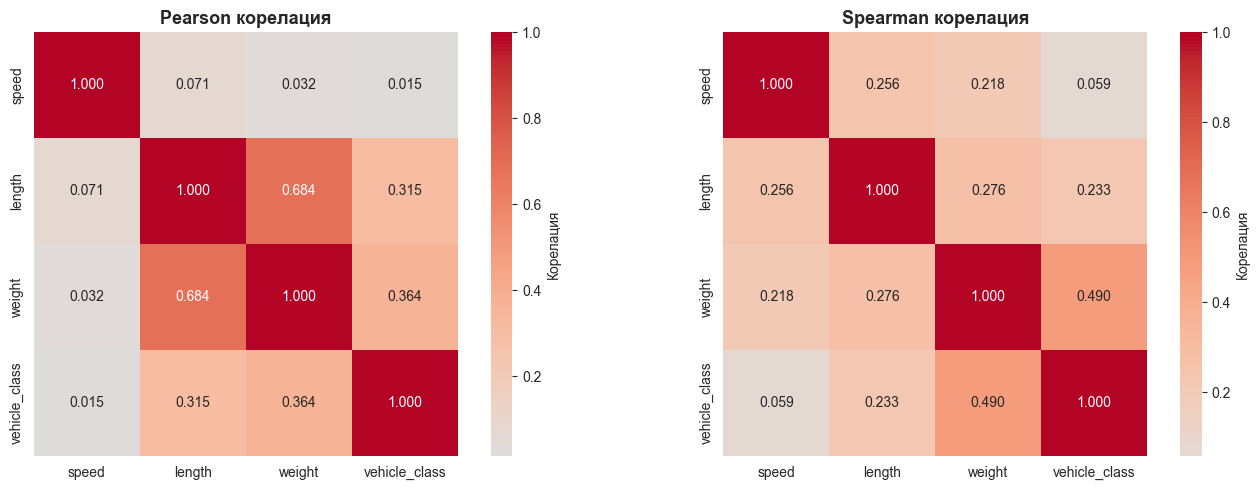


Средни стойности по vehicle_class:
               speed   length   weight
vehicle_class                         
0               46.0   4060.8    113.0
1               47.7   3797.8   1827.4
2               49.9   5482.1   3409.8
3               45.1   7305.8   6231.5
4               38.8   8445.8  15280.7
5               43.8  11860.9  19408.3
6               44.8  10177.9  12921.7
7               54.9   2704.1   1781.7
23              44.1  15051.6  30080.3
99              42.1  11027.8  13303.4


In [2]:
print("=" * 60)
print("АНАЛИЗ 1: КОРЕЛАЦИОНЕН АНАЛИЗ")
print("=" * 60)

# Корелация между числовите колони
numeric_cols = ["speed", "length", "weight", "vehicle_class"]
corr_matrix = df[numeric_cols].corr(method="pearson")

print("Pearson корелационна матрица:")
print(corr_matrix.round(3).to_string())

# Визуализация
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Pearson
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm",
            center=0, ax=ax1, square=True,
            cbar_kws={"label": "Корелация"})
ax1.set_title("Pearson корелация", fontsize=13, fontweight="bold")

# Spearman - по-добър за нелинейни връзки
corr_spearman = df[numeric_cols].corr(method="spearman")
sns.heatmap(corr_spearman, annot=True, fmt=".3f", cmap="coolwarm",
            center=0, ax=ax2, square=True,
            cbar_kws={"label": "Корелация"})
ax2.set_title("Spearman корелация", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("feature_corr.png", dpi=150, bbox_inches="tight")
plt.show()

# Корелация по vehicle_class
print("\nСредни стойности по vehicle_class:")
print(df.groupby("vehicle_class")[["speed","length","weight"]]
      .mean().round(1).to_string())

In [3]:
print("=" * 60)
print("АНАЛИЗ 2: ВАРИАБИЛНОСТ ПО ВРЕМЕВИ ИНТЕРВАЛ")
print("=" * 60)

intervals = {"15min": "15min", "1h": "1h", "1D": "1D"}

for name, freq in intervals.items():
    agg = df.groupby(df["date"].dt.floor(freq)).size()
    print(f"\nИнтервал {name}:")
    print(f"  Общо интервали       : {len(agg):,}")
    
    # Пълна поредица
    full = pd.date_range(df["date"].min().floor(freq),
                         df["date"].max().floor(freq), freq=freq)
    missing = len(full) - len(agg)
    print(f"  Пълни интервали      : {len(full):,}")
    print(f"  Липсващи интервали   : {missing:,} ({missing/len(full)*100:.1f}%)")
    print(f"  Средно записи/интервал: {agg.mean():.1f}")
    print(f"  Min записи/интервал  : {agg.min()}")
    print(f"  Max записи/интервал  : {agg.max()}")

АНАЛИЗ 2: ВАРИАБИЛНОСТ ПО ВРЕМЕВИ ИНТЕРВАЛ

Интервал 15min:
  Общо интервали       : 72,726
  Пълни интервали      : 105,216
  Липсващи интервали   : 32,490 (30.9%)
  Средно записи/интервал: 154.6
  Min записи/интервал  : 1
  Max записи/интервал  : 693

Интервал 1h:
  Общо интервали       : 18,455
  Пълни интервали      : 26,304
  Липсващи интервали   : 7,849 (29.8%)
  Средно записи/интервал: 609.3
  Min записи/интервал  : 1
  Max записи/интервал  : 2457

Интервал 1D:
  Общо интервали       : 815
  Пълни интервали      : 1,096
  Липсващи интервали   : 281 (25.6%)
  Средно записи/интервал: 13797.6
  Min записи/интервал  : 1
  Max записи/интервал  : 32467


In [4]:
print("=" * 60)
print("АНАЛИЗ 3: ИНФОРМАЦИОННА СТОЙНОСТ НА КОЛОНИТЕ")
print("=" * 60)

# Агрегираме по час и проверяваме вариабилността
df["hour_ts"] = df["date"].dt.floor("h")

hourly = df.groupby("hour_ts").agg(
    volume      = ("speed", "size"),
    avg_speed   = ("speed", "mean"),
    avg_length  = ("length", "mean"),
    avg_weight  = ("weight", "mean"),
    std_speed   = ("speed", "std"),
    std_length  = ("length", "std")
).reset_index()

print("Вариабилност на агрегираните колони (CV = std/mean):")
for col in ["volume", "avg_speed", "avg_length", "avg_weight"]:
    cv = hourly[col].std() / hourly[col].mean()
    print(f"  {col:15}: mean={hourly[col].mean():.1f}, "
          f"std={hourly[col].std():.1f}, CV={cv:.3f}")

# Корелация между агрегираните колони
print(f"\nКорелация между агрегираните колони:")
agg_cols = ["volume", "avg_speed", "avg_length", "avg_weight"]
print(hourly[agg_cols].corr().round(3).to_string())

# Колко от вариацията в avg_speed се обяснява от volume?
from numpy.polynomial import polynomial as P
corr_vol_speed = hourly[["volume", "avg_speed"]].corr().iloc[0,1]
print(f"\nКорелация volume ↔ avg_speed : {corr_vol_speed:.3f}")
print(f"R²                           : {corr_vol_speed**2:.3f}")

АНАЛИЗ 3: ИНФОРМАЦИОННА СТОЙНОСТ НА КОЛОНИТЕ
Вариабилност на агрегираните колони (CV = std/mean):
  volume         : mean=609.3, std=661.5, CV=1.086
  avg_speed      : mean=48.7, std=3.6, CV=0.074
  avg_length     : mean=4634.7, std=755.7, CV=0.163
  avg_weight     : mean=1930.8, std=1323.3, CV=0.685

Корелация между агрегираните колони:
            volume  avg_speed  avg_length  avg_weight
volume       1.000     -0.261      -0.576       0.251
avg_speed   -0.261      1.000       0.197      -0.222
avg_length  -0.576      0.197       1.000      -0.060
avg_weight   0.251     -0.222      -0.060       1.000

Корелация volume ↔ avg_speed : -0.261
R²                           : 0.068


In [5]:
print("=" * 60)
print("АНАЛИЗ 4: VEHICLE CLASS РАЗБИВКА")
print("=" * 60)

# Дял на всеки клас по час
df["hour_ts"] = df["date"].dt.floor("h")

vc_hourly = (df.groupby(["hour_ts", "vehicle_class"])
               .size()
               .reset_index(name="count"))

vc_pivot = (vc_hourly.pivot(index="hour_ts", 
                             columns="vehicle_class", 
                             values="count")
                      .fillna(0))

# Корелация между класовете
print("Корелация между броя ПС по клас (почасово):")
print(vc_pivot.corr().round(3).to_string())

# CV за всеки клас
print(f"\nВариабилност по клас (CV):")
for col in vc_pivot.columns:
    cv = vc_pivot[col].std() / vc_pivot[col].mean()
    pct = df[df["vehicle_class"]==col].shape[0] / len(df) * 100
    print(f"  Клас {col:3}: CV={cv:.3f}, дял={pct:.2f}%")

# Корелация с общия volume
vc_pivot["total"] = vc_pivot.sum(axis=1)
print(f"\nКорелация на всеки клас с общия volume:")
for col in [c for c in vc_pivot.columns if c != "total"]:
    corr = vc_pivot[col].corr(vc_pivot["total"])
    print(f"  Клас {col:3}: {corr:.3f}")

АНАЛИЗ 4: VEHICLE CLASS РАЗБИВКА
Корелация между броя ПС по клас (почасово):
vehicle_class     0      1      2      3      4      5      6      7      23     99
vehicle_class                                                                      
0              1.000  0.088  0.144  0.062 -0.011  0.096  0.034  0.247  0.054  0.063
1              0.088  1.000  0.900  0.778  0.488  0.778  0.684  0.751  0.091  0.115
2              0.144  0.900  1.000  0.903  0.661  0.889  0.802  0.761  0.027  0.031
3              0.062  0.778  0.903  1.000  0.672  0.859  0.865  0.700 -0.042 -0.034
4             -0.011  0.488  0.661  0.672  1.000  0.653  0.616  0.379 -0.047 -0.046
5              0.096  0.778  0.889  0.859  0.653  1.000  0.808  0.646  0.147  0.146
6              0.034  0.684  0.802  0.865  0.616  0.808  1.000  0.573  0.017  0.023
7              0.247  0.751  0.761  0.700  0.379  0.646  0.573  1.000 -0.069 -0.069
23             0.054  0.091  0.027 -0.042 -0.047  0.147  0.017 -0.069  1.000  0.876

АНАЛИЗ 5: АНАЛИЗ ПО ПОСОКА
Корелация Център ↔ Околовръстно: 0.981

Център:
  mean=325.9, std=347.2, CV=1.066

Околовръстно:
  mean=283.5, std=317.5, CV=1.120


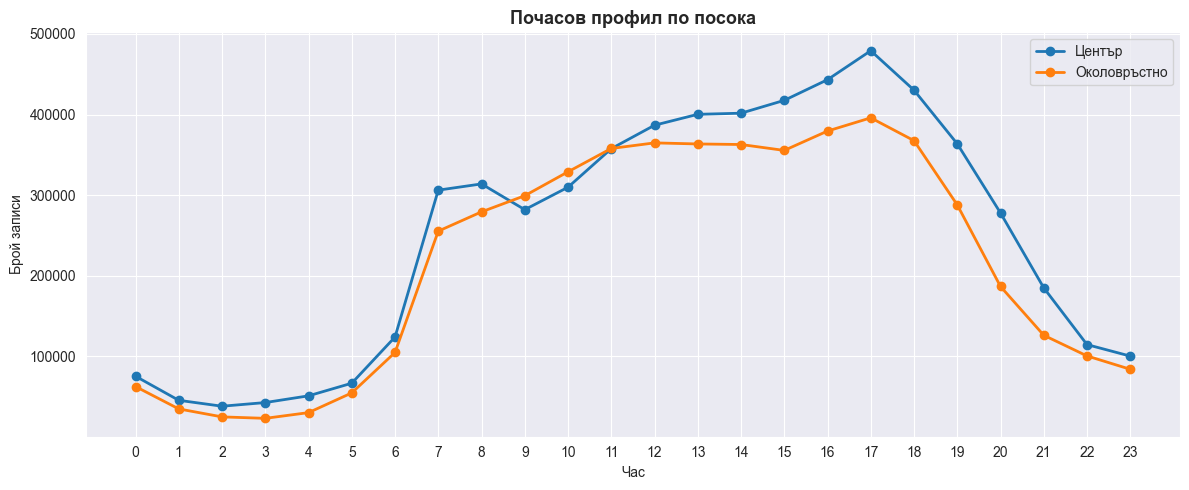

In [6]:
print("=" * 60)
print("АНАЛИЗ 5: АНАЛИЗ ПО ПОСОКА")
print("=" * 60)

# Агрегиране по час и посока
hourly_dir = (df.groupby([df["date"].dt.floor("h"), "direction"])
               .size()
               .reset_index(name="count"))

hourly_pivot = (hourly_dir.pivot(index="date", 
                                  columns="direction", 
                                  values="count")
                           .fillna(0))

hourly_pivot.columns = ["Okolovrastno", "Centar"]

# Корелация между посоките
corr_dir = hourly_pivot["Centar"].corr(hourly_pivot["Okolovrastno"])
print(f"Корелация Център ↔ Околовръстно: {corr_dir:.3f}")

# CV по посока
for col, name in [("Centar", "Център"), ("Okolovrastno", "Околовръстно")]:
    cv = hourly_pivot[col].std() / hourly_pivot[col].mean()
    print(f"\n{name}:")
    print(f"  mean={hourly_pivot[col].mean():.1f}, "
          f"std={hourly_pivot[col].std():.1f}, CV={cv:.3f}")

# Среден hourly profile по посока
df["hour"] = df["date"].dt.hour
hourly_profile = (df.groupby(["hour", "direction"])
                    .size()
                    .reset_index(name="count"))

fig, ax = plt.subplots(figsize=(12, 5))
for direction in ["Център", "Околовръстно"]:
    sub = hourly_profile[hourly_profile["direction"] == direction]
    ax.plot(sub["hour"], sub["count"], 
            marker="o", linewidth=2, label=direction)

ax.set_title("Почасов профил по посока", fontsize=13, fontweight="bold")
ax.set_xlabel("Час")
ax.set_ylabel("Брой записи")
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.savefig("feature_direction_profile.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
print("=" * 60)
print("ФИНАЛНО РЕШЕНИЕ — FEATURE SELECTION")
print("=" * 60)

print("""
КОЛОНИ ЗА ОТПАДАНЕ:
  ✗ plate        — чувствителни данни, отпада при агрегиране
  ✗ country      — 40% null, не е релевантна за трафик анализ
  ✗ weight       — системна повреда на сензора (L1, L4, L5)

КОЛОНИ ЗА ЗАПАЗВАНЕ:
  ✓ date         — задължителна за времевия ред
  ✓ direction    — за агрегиране по посока
  ✓ lane         — за агрегиране по лента
  ✓ vehicle_class— за разбивка по тип ПС
  ✓ speed        — за avg_speed агрегат
  ✓ length       — за avg_length агрегат

АГРЕГИРАНИ ХАРАКТЕРИСТИКИ:
  ✓ volume       — брой преминали ПС (най-важна!)
  ✓ avg_speed    — средна скорост (CV=0.074, ниска но реална)
  ✓ avg_length   — средна дължина (CV=0.163)

ВРЕМЕВИ ИНТЕРВАЛ: 1 час
АГРЕГИРАНЕ ПО:    посока (Център/Околовръстно)
""")

ФИНАЛНО РЕШЕНИЕ — FEATURE SELECTION

КОЛОНИ ЗА ОТПАДАНЕ:
  ✗ plate        — чувствителни данни, отпада при агрегиране
  ✗ country      — 40% null, не е релевантна за трафик анализ
  ✗ weight       — системна повреда на сензора (L1, L4, L5)

КОЛОНИ ЗА ЗАПАЗВАНЕ:
  ✓ date         — задължителна за времевия ред
  ✓ direction    — за агрегиране по посока
  ✓ lane         — за агрегиране по лента
  ✓ vehicle_class— за разбивка по тип ПС
  ✓ speed        — за avg_speed агрегат
  ✓ length       — за avg_length агрегат

АГРЕГИРАНИ ХАРАКТЕРИСТИКИ:
  ✓ volume       — брой преминали ПС (най-важна!)
  ✓ avg_speed    — средна скорост (CV=0.074, ниска но реална)
  ✓ avg_length   — средна дължина (CV=0.163)

ВРЕМЕВИ ИНТЕРВАЛ: 1 час
АГРЕГИРАНЕ ПО:    посока (Център/Околовръстно)



In [8]:
print("=" * 60)
print("ИНФОРМАЦИОННА СТОЙНОСТ НА avg_length")
print("=" * 60)

# Как се променя avg_length по час от денонощието?
df["hour"] = df["date"].dt.hour
length_by_hour = df.groupby("hour")["length"].mean()
print("Средна дължина по час:")
print(length_by_hour.round(0).to_string())

# Как се променя по ден от седмицата?
df["dow"] = df["date"].dt.dayofweek
length_by_dow = df.groupby("dow")["length"].mean()
dow_labels = ["Пон","Вт","Ср","Чет","Пет","Съб","Нед"]
print("\nСредна дължина по ден от седмицата:")
for i, val in enumerate(length_by_dow):
    print(f"  {dow_labels[i]}: {val:.0f} мм")

# Корелация avg_length с volume по час
hourly = df.groupby(df["date"].dt.floor("h")).agg(
    volume     = ("speed", "size"),
    avg_length = ("length", "mean"),
    avg_speed  = ("speed", "mean")
).reset_index()

print(f"\nКорелация avg_length ↔ volume    : {hourly['avg_length'].corr(hourly['volume']):.3f}")
print(f"Корелация avg_length ↔ avg_speed : {hourly['avg_length'].corr(hourly['avg_speed']):.3f}")

# Вариацията на avg_length обяснена ли е от vehicle_class mix?
vc_hourly = df.groupby(df["date"].dt.floor("h")).apply(
    lambda x: (x["vehicle_class"] == 1).mean()
).reset_index(name="pct_class1")

merged = hourly.merge(vc_hourly, on="date")
print(f"Корелация avg_length ↔ % клас 1  : {merged['avg_length'].corr(merged['pct_class1']):.3f}")

ИНФОРМАЦИОННА СТОЙНОСТ НА avg_length
Средна дължина по час:
hour
0     4007.0
1     4150.0
2     4489.0
3     4381.0
4     4482.0
5     4608.0
6     4412.0
7     4182.0
8     4245.0
9     4269.0
10    4232.0
11    4225.0
12    4187.0
13    4188.0
14    4181.0
15    4167.0
16    4108.0
17    4065.0
18    4041.0
19    4053.0
20    4051.0
21    4052.0
22    4078.0
23    4040.0

Средна дължина по ден от седмицата:
  Пон: 4244 мм
  Вт: 4223 мм
  Ср: 4226 мм
  Чет: 4215 мм
  Пет: 4212 мм
  Съб: 3999 мм
  Нед: 3958 мм

Корелация avg_length ↔ volume    : -0.576
Корелация avg_length ↔ avg_speed : 0.197
Корелация avg_length ↔ % клас 1  : -0.311
